# Fig. 6 — Axion response of Y₂Ir₂O₇ (paper `draft/main_draft.tex`, `fig:yio`)

Run all; the last cell writes `paper/figures/fig6.pdf` (+ `.png`). Production window `f12.422_w22.644_k8`.

| panel | content | data |
|---|---|---|
| (a) | k convergence of ∂θ/∂Q at Q = 0.01 Å for the three Γ₂⁻ patterns: \|value on N³ / value on 12³ − 1\| for both endpoint estimates (filled: undistorted, open: displaced), and the Chern–Simons 3-form at N = 10 against 12 | uniform grids `dtheta_nk{4,6,8,12}_GM2-_p*_Q0.01` (2026-11-03, `analysis/validation/2026-11-03_k_sweeps/c2_variant.sh`), N = 10 the production `dtheta_GM2-_p*_Q0.01`; `cs/theta_cs.npz` |
| (b) | curvature symmetry residual of the pattern-`SYMMETRY_PATTERN` model (1: Y) under each of the 23 operations of −4′3m′ besides E, by part, and the controls: C4z and S4z (non-symmetries, 200%) and C4z·T (in the undistorted group, broken by the displacement) | `symmetry_GM2-_p<SYMMETRY_PATTERN>_Q0.01/out/symmetry_mode.npz` (`tests/symmetry/run_yio_symmetry.{sh,py}`, cluster) |
| (c) | the three physical Γ₂⁻ modes on the Ir₄ tetrahedron of Fig. 1 (O(48f) on its edges, eight Y around it, seen along [001]): arrows = displacement, largest `ARROW` Å; title: frequency and ∂θ per Å of total displacement | `mode_couplings.log` (`analysis/yio/phonon/mode_couplings.py`: Γ₂⁻ basis coefficients c), SMODES vectors from the Q = 0.01 Å inputs |
| (d) | c₂ (mean of the two ends) of pattern 3 on the plane through Γ perpendicular to [110], in the first Brillouin zone, interpolated from the 12³ grid | `dtheta_nk12_GM2-_p3_Q0.01` |


In [1]:
# ---- settings
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, to_rgb
from matplotlib.patches import Circle, FancyArrowPatch
from scipy.ndimage import map_coordinates

ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data/Y2Ir2O7"
WINDOW = DATA / "windows/f12.422_w22.644_k8"      # production window
PATTERNS = (1, 2, 3)
LABELS = {1: "Y", 2: "Ir", 3: r"O$_{48f}$"}
COLORS = {1: "#2b6cb0", 2: "#7b3294", 3: "#d9821e"}   # Fig. 7 palette by role (as Figs. 1, 3, 5)
# (a) nk sweep at Q = 0.01 Å: uniform N^3 grids; N = 10 is the production pair (dtheta.npz), the others dtheta_nk<N>_*
SWEEP_NK = (4, 6, 8, 10, 12)
SWEEP = {(m, n): WINDOW / (f"dtheta_GM2-_p{m}_Q0.01" if n == 10 else f"dtheta_nk{n}_GM2-_p{m}_Q0.01")
         for m in PATTERNS for n in SWEEP_NK}
CS = {m: WINDOW / f"dtheta_GM2-_p{m}_Q0.01/cs/theta_cs.npz" for m in PATTERNS}   # 3-form at nk 10, 12
# (b) symmetry residual per operation of one displaced structure (tests/symmetry/run_yio_symmetry.py, cluster)
SYMMETRY_PATTERN = 1                              # 1, 2 or 3 (each has its own symmetry_<structure>/ folder)
SYMMETRY = WINDOW / f"symmetry_GM2-_p{SYMMETRY_PATTERN}_Q0.01/out/symmetry_mode.npz"
# (c) the three physical modes: Γ2- basis coefficients from mode_couplings.log, drawn on the Fig. 1 cluster
MODES_LOG = WINDOW / "mode_couplings.log"
BASE_SCF_IN = DATA / "dft/base/scf/out/Y2Ir2O7.scf.in"
PATTERN_IN = {m: DATA / f"dft/GM2-_p{m}_Q0.01/scf/out/Y2Ir2O7.scf.in" for m in PATTERNS}
Q = 0.01
ARROW = 1.3                                       # Å, the largest displacement arrow of each mode
RADII = {"Ir": 0.40, "Y": 0.36, "O": 0.26}
ATOM_COLORS = {"Ir": "#7b3294", "Y": "#2b6cb0", "O": "#d9821e"}
MODE_ARROW_COLOR = "#c0392b"                      # Fig. 7's displacement arrows
# (d) c2 on the plane through Γ spanned by b1, b2, interpolated from the densest grid of the sweep
MAP_PATTERN = 3
MAP_NK = 12
MAP_GRID = 301
FIGSIZE = (7.0, 5.0)
FONT_SIZE = 8
SAVE_FIG = ROOT / "paper/figures/fig6.pdf"        # (+ .png); or None
# ---------------


In [2]:
# ---- data
def pair_c2(folder):
    """(k list, c2 (N, 2 ends)) of a pair folder: step 7's c2.npz, or else the step-6 chunks."""
    kl = dict(np.load(folder / "klist.npz"))
    if (folder / "c2.npz").exists():
        return kl, np.load(folder / "c2.npz")["c2"]
    c2 = np.full((len(kl["k"]), 2), np.nan, complex)
    for f in sorted(folder.glob("c2/out*/chunks/chunk_*.npz")):
        z = np.load(f)
        c2[z["idx"]] = z["c2"]
    assert not np.isnan(c2.real).any(), f"{folder}: missing chunks"
    return kl, c2


sweep = {}                                         # pattern: (N, ends) array of dθ/dQ, uniform grids (mean of c2)
for m in PATTERNS:
    sweep[m] = np.array([pair_c2(SWEEP[(m, n)])[1].real.mean(0) for n in SWEEP_NK])
    ref = sweep[m][-1]
    print(f"pattern {m}: " + "  ".join(f"N={n} {v[0]:+.6f}/{v[1]:+.6f}" for n, v in zip(SWEEP_NK, sweep[m]))
          + f"   |rel. change from N=12| at N=8: {np.abs(sweep[m][2] / ref - 1).max():.1e}")
cs = {m: np.load(f) for m, f in CS.items()}
for m, z in cs.items():
    print(f"pattern {m}: 3-form [θ(Q) − θ(0)]/Q at nk {list(z['nks'])}: {z['dtheta'].round(7)}")

sym = dict(np.load(SYMMETRY, allow_pickle=True))
n_ops = int(sym["n_ops"])
print(f"symmetry of pattern {SYMMETRY_PATTERN}: {n_ops - 1} operations besides E; controls "
      + ", ".join(f"{n} {v:.1%}" for n, v in zip(sym["names"][n_ops:], sym["rows"][n_ops:, 4])))


def read_pw_input(path):
    text = Path(path).read_text()
    lines = text.splitlines()
    i = next(k for k, l in enumerate(lines) if l.startswith("CELL_PARAMETERS"))
    cell = np.array([[float(x) for x in lines[i + j].split()[:3]] for j in (1, 2, 3)])
    i = next(k for k, l in enumerate(lines) if l.startswith("ATOMIC_POSITIONS"))
    labels, pos = [], []
    for line in lines[i + 1:]:
        s = line.split()
        if len(s) < 4 or not re.match(r"[A-Z][a-z]?\d*$", s[0]):
            break
        labels.append(s[0]); pos.append([float(x) for x in s[1:4]])
    return cell, labels, np.array(pos)


cell, labels, pos = read_pw_input(BASE_SCF_IN)
v = {m: (read_pw_input(PATTERN_IN[m])[2] - pos) / Q for m in PATTERNS}      # SMODES vectors (entries 0, ±1)
modes = []                                         # (ω, c (3,), dθ/dq, per Å) from the log
for line in MODES_LOG.read_text().splitlines():
    g = re.match(r"\s+([\d.]+)\s+\[\s*([-\d.e]+)\s+([-\d.e]+)\s+([-\d.e]+)\s*\]\s+\[.*?\]\s+([-+\d.e]+)\s+([-+\d.e]+)", line)
    if g:
        modes.append((float(g[1]), np.array([float(g[i]) for i in (2, 3, 4)]), float(g[5]), float(g[6])))
assert len(modes) == 3, MODES_LOG
a_cub = np.linalg.norm(cell[0]) * np.sqrt(2)
centre = pos[labels.index("Ir1")] + np.full(3, a_cub / 8)        # the Ir4 tetrahedron of Fig. 1
shifts = np.array(np.meshgrid(*[range(-2, 3)] * 3)).reshape(3, -1).T @ cell
cluster = []                                       # (element, r from centre, displacement per unit amplitude of each mode)
for i, (lab, x) in enumerate(zip(labels, pos)):
    el = re.match(r"[A-Z][a-z]?", lab).group(0)
    for s in shifts:
        r = x + s - centre
        d = np.linalg.norm(r)
        if (el in ("Ir", "O") and d < 2.3) or (el == "Y" and d < 4.3 and abs(r[2]) < 3.0):   # the Fig. 1 cluster, [001] view
            cluster.append((el, r, [sum(c[k] * v[m][i] for k, m in enumerate(PATTERNS)) for _, c, _, _ in modes]))

kl, c2 = pair_c2(WINDOW / f"dtheta_nk{MAP_NK}_GM2-_p{MAP_PATTERN}_Q0.01")
n = MAP_NK
grid = np.full((n, n, n), np.nan)
idx = np.rint(kl["k"] * n).astype(int) % n
grid[idx[:, 0], idx[:, 1], idx[:, 2]] = c2.real.mean(1)
B = 2 * np.pi * np.linalg.inv(cell).T
e1 = B[0] / np.linalg.norm(B[0]); e2 = B[1] - (B[1] @ e1) * e1; e2 /= np.linalg.norm(e2)
normal = np.cross(e1, e2)
Rk = 1.05 * np.linalg.norm(B, axis=1).max()
sgrid = np.linspace(-Rk, Rk, MAP_GRID)
S, T = np.meshgrid(sgrid, sgrid, indexing="xy")
kc = S[..., None] * e1 + T[..., None] * e2
G = np.array(np.meshgrid(*[range(-2, 3)] * 3, indexing="ij")).reshape(3, -1).T @ B
G = G[np.linalg.norm(G, axis=1) > 1e-9]
inside = np.all(np.einsum("ijk,gk->ijg", kc, G) <= 0.5 * (G ** 2).sum(1), axis=-1)
coords = ((kc @ np.linalg.inv(B)) % 1.0 * n).transpose(2, 0, 1)
cmap_vals = np.where(inside, map_coordinates(grid, coords, order=3, mode="grid-wrap"), np.nan)
print(f"map: pattern {MAP_PATTERN} on {n}^3, plane normal {(normal / np.abs(normal).max()).round(3)}")


pattern 1: N=4 -0.017119/-0.017214  N=6 -0.017118/-0.017214  N=8 -0.017114/-0.017210  N=10 -0.017114/-0.017210  N=12 -0.017114/-0.017210   |rel. change from N=12| at N=8: 5.0e-06
pattern 2: N=4 +0.051503/+0.051120  N=6 +0.054978/+0.054555  N=8 +0.055021/+0.054596  N=10 +0.055021/+0.054596  N=12 +0.055021/+0.054597   |rel. change from N=12| at N=8: 3.7e-06
pattern 3: N=4 +0.062362/+0.062327  N=6 +0.063860/+0.063824  N=8 +0.063867/+0.063830  N=10 +0.063867/+0.063830  N=12 +0.063867/+0.063830   |rel. change from N=12| at N=8: 1.3e-06
pattern 1: 3-form [θ(Q) − θ(0)]/Q at nk [np.int64(10), np.int64(12)]: [-0.0171272 -0.0171273]
pattern 2: 3-form [θ(Q) − θ(0)]/Q at nk [np.int64(10), np.int64(12)]: [0.0549239 0.054924 ]
pattern 3: 3-form [θ(Q) − θ(0)]/Q at nk [np.int64(10), np.int64(12)]: [0.063844 0.063844]
symmetry of pattern 1: 23 operations besides E; controls control C4z 200.0%, control C4z T 1.8%, control S4z 199.4%
map: pattern 3 on 12^3, plane normal [1. 1. 0.]


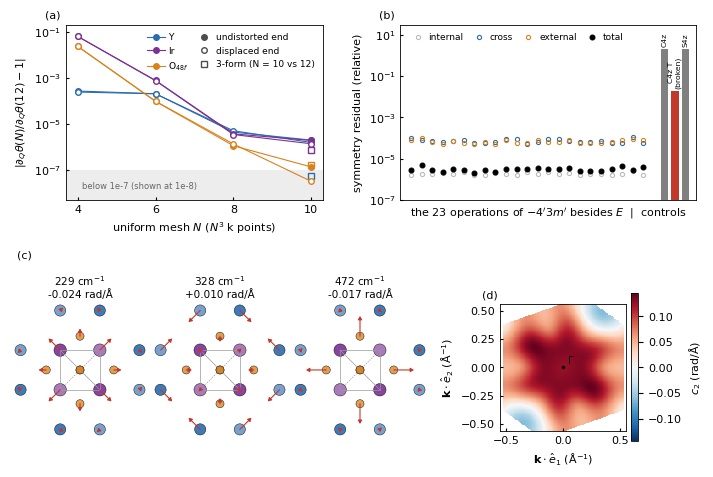

In [3]:
# ---- draw
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6, "mathtext.fontset": "dejavusans"})
fig = plt.figure(figsize=FIGSIZE)
top = fig.add_gridspec(1, 2, width_ratios=[1, 1.15], wspace=0.28, left=0.08, right=0.98, top=0.95, bottom=0.6)
bot = fig.add_gridspec(1, 3, wspace=0.0, left=0.0, right=0.6, top=0.45, bottom=0.07)
bot_d = fig.add_gridspec(1, 1, left=0.7, right=0.92, top=0.45, bottom=0.08)
ax_a, ax_b = fig.add_subplot(top[0, 0]), fig.add_subplot(top[0, 1])
ax_c = [fig.add_subplot(bot[0, j]) for j in range(3)]
ax_d = fig.add_subplot(bot_d[0, 0])

# (a) |dθ/dQ(N) / dθ/dQ(12) − 1| for both ends, and the 3-form at N = 10 vs 12
for m in PATTERNS:
    ref = sweep[m][-1]
    for e, mfc in ((0, COLORS[m]), (1, "white")):
        dev = np.abs(sweep[m][:-1, e] / ref[e] - 1)
        ax_a.plot(SWEEP_NK[:-1], np.maximum(dev, 1e-8), "o-", color=COLORS[m], mfc=mfc, ms=4, lw=0.8,
                  label=LABELS[m] if e == 0 else None)
    z = cs[m]
    d = abs(z["dtheta"][0] / z["dtheta"][-1] - 1)
    ax_a.plot([10], [max(d, 1e-8)], "s", color=COLORS[m], ms=5, mfc="none", mew=1)
ax_a.plot([], [], "o", color="0.3", ms=4, label="undistorted end"); ax_a.plot([], [], "o", color="0.3", mfc="white", ms=4, label="displaced end")
ax_a.plot([], [], "s", color="0.3", mfc="none", ms=5, label="3-form (N = 10 vs 12)")
ax_a.set(yscale="log", ylim=(5e-9, 0.2), xticks=SWEEP_NK[:-1], xlabel="uniform mesh $N$ ($N^3$ k points)",
         ylabel=r"$|\partial_Q\theta(N)/\partial_Q\theta(12) - 1|$")
ax_a.axhspan(1e-9, 1e-7, color="0.93", lw=0)
ax_a.text(4.1, 2e-8, "below 1e-7 (shown at 1e-8)", fontsize=FONT_SIZE - 2, color="0.4", va="center")
ax_a.legend(fontsize=FONT_SIZE - 1.5, frameon=False, ncol=2, loc="upper right", handletextpad=0.3, columnspacing=0.8)

# (b) symmetry residual per operation, pattern SYMMETRY_PATTERN, and the controls
rows, names = sym["rows"], sym["names"]
order = np.arange(1, n_ops)
parts = (("internal", 1, "#bbbbbb"), ("cross", 2, "#2b6cb0"), ("external", 3, "#d9821e"), ("total", 4, "black"))
x = np.arange(len(order))
for name, col, color in parts:
    ax_b.plot(x, np.maximum(rows[order, col], 1e-8), "o", ms=3 if name != "total" else 3.5, color=color,
              mfc=color if name == "total" else "none", mew=0.8, label=name)
xc = len(order) + 1 + np.arange(len(names) - n_ops)
broken = sym.get("control_broken", np.zeros(len(xc), bool))
ax_b.bar(xc, rows[n_ops:, 4], color=["#c0392b" if b else "0.5" for b in broken], width=0.7)
for xx, nm, b in zip(xc, names[n_ops:], broken):
    ax_b.text(xx, rows[n_ops:, 4][list(xc).index(xx)] * 1.4, nm.replace("control ", "") + ("\n(broken)" if b else ""),
              ha="center", va="bottom", fontsize=FONT_SIZE - 2.5, rotation=90)
ax_b.set(yscale="log", ylim=(1e-7, 30), xlim=(-1, xc[-1] + 1), xticks=[],
         ylabel="symmetry residual (relative)", xlabel=f"the {n_ops - 1} operations of $-4'3m'$ besides $E$  |  controls")
ax_b.legend(fontsize=FONT_SIZE - 1.5, frameon=False, ncol=4, loc="upper left", handletextpad=0.2, columnspacing=0.7)

# (c) the three modes on the Ir4 tetrahedron + O(48f) + Y ring, viewed along [001]
for j, (ax, (w, c, dq, perA)) in enumerate(zip(ax_c, modes)):
    disp = np.array([u[j] for _, _, u in cluster])
    scale = ARROW / np.linalg.norm(disp, axis=1).max()          # the largest displacement drawn ARROW long
    irs = [r for el, r, _ in cluster if el == "Ir"]
    for p in range(4):
        for q in range(p + 1, 4):
            back = (irs[p][2] + irs[q][2]) / 2 < -0.5
            ax.plot([irs[p][0], irs[q][0]], [irs[p][1], irs[q][1]], color="0.6", lw=0.5, ls=(0, (2, 1.5)) if back else "-",
                    zorder=1 if back else 25)
    zs = np.array([r[2] for _, r, _ in cluster])
    for k in np.argsort(zs):
        el, r, _ = cluster[k]
        f = 0.45 * (zs.max() - r[2]) / (zs.max() - zs.min())
        ax.add_patch(Circle(r[:2], RADII[el], fc=np.array(to_rgb(ATOM_COLORS[el])) * (1 - f) + f, ec="k", lw=0.3,
                            zorder=10 + r[2]))
        d = disp[k] * scale
        if np.hypot(*d[:2]) > 0.15:
            ax.add_patch(FancyArrowPatch(r[:2], r[:2] + d[:2], arrowstyle="-|>,head_length=2.0,head_width=1.2", lw=0.8,
                                         color=MODE_ARROW_COLOR, shrinkA=0, shrinkB=0, zorder=40))
    ax.set_aspect("equal"); ax.axis("off"); ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5)
    ax.set_title(f"{w:.0f} cm$^{{-1}}$\n{perA:+.3f} rad/Å", fontsize=FONT_SIZE - 0.5, pad=1)

# (d) c2 on the plane through Γ (b1, b2), first Brillouin zone
vm = np.nanmax(np.abs(cmap_vals))
im = ax_d.pcolormesh(S, T, cmap_vals, cmap="RdBu_r", norm=TwoSlopeNorm(0, -vm, vm), shading="auto", rasterized=True)
ax_d.set(aspect="equal", xlabel=r"$\mathbf{k}\cdot\hat e_1$ (Å$^{-1}$)", ylabel=r"$\mathbf{k}\cdot\hat e_2$ (Å$^{-1}$)")
half = 1.05 * np.nanmax(np.abs(np.where(np.isnan(cmap_vals), np.nan, S)))
ax_d.set(xlim=(-half, half), ylim=(-half, half))
fig.colorbar(im, ax=ax_d, shrink=0.8, pad=0.03, label=r"$c_2$ (rad/Å)")
ax_d.plot([0], [0], "k.", ms=3); ax_d.annotate(r"$\Gamma$", (0, 0), xytext=(3, 3), textcoords="offset points", fontsize=FONT_SIZE - 1)

for ax, tag in ((ax_a, "(a)"), (ax_b, "(b)"), (ax_d, "(d)")):
    ax.text(-0.02, 1.03, tag, transform=ax.transAxes, fontsize=FONT_SIZE, va="bottom", ha="right")
fig.text(0.01, 0.5, "(c)", fontsize=FONT_SIZE, va="top")
for ax in (ax_a, ax_b, ax_d):
    ax.tick_params(direction="in", length=2, which="both")
if SAVE_FIG:
    fig.savefig(SAVE_FIG)
    fig.savefig(SAVE_FIG.with_suffix(".png"), dpi=300)
plt.show()
plt.rcdefaults()
